<a href="https://colab.research.google.com/github/adrielpermata/projek-gajah-baru-filter/blob/main/projek_data_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset (1).csv
Data berhasil dibaca


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Ukuran dataset: (100000, 9)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB

Statistik deskriptif:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000,100000.000000,100000.00000,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000
unique,3,NaN,NaN,NaN,6,NaN,NaN,NaN,NaN
top,Female,NaN,NaN,NaN,No Info,NaN,NaN,NaN,NaN
freq,58552,NaN,NaN,NaN,35816,NaN,NaN,NaN,NaN
mean,NaN,41.885856,0.07485,0.039420,NaN,27.320767,5.527507,138.058060,0.085000
std,NaN,22.516840,0.26315,0.194593,NaN,6.636783,1.070672,40.708136,0.278883
min,NaN,0.080000,0.00000,0.000000,NaN,10.010000,3.500000,80.000000,0.000000
25%,NaN,24.000000,0.00000,0.000000,NaN,23.630000,4.800000,100.000000,0.000000
50%,NaN,43.000000,0.00000,0.000000,NaN,27.320000,5.800000,140.000000,0.000000
75%,NaN,60.000000,0.00000,0.000000,NaN,29.580000,6.200000,159.000000,0.000000


Missing value:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Jumlah data duplikat:
3854
Missing value setelah pembersihan:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Ukuran data setelah pembersihan: (96146, 9)


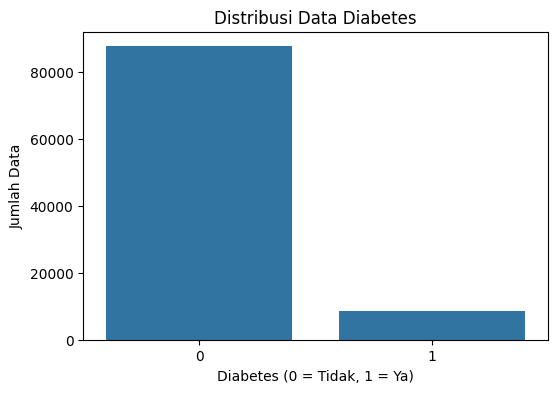

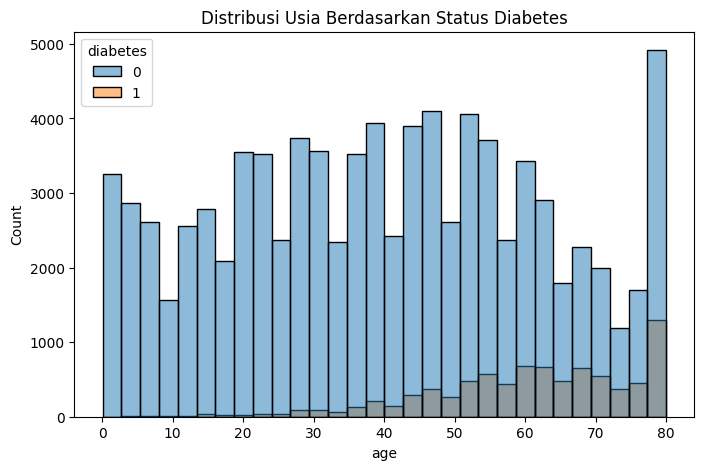

Data setelah encoding:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


Jumlah data training: 76916
Jumlah data testing: 19230
Model berhasil dilatih
Akurasi model: 96.98 %

Classification Report:
                precision    recall  f1-score   support

Tidak Diabetes       0.97      1.00      0.98     17534
      Diabetes       0.95      0.69      0.80      1696

      accuracy                           0.97     19230
     macro avg       0.96      0.84      0.89     19230
  weighted avg       0.97      0.97      0.97     19230



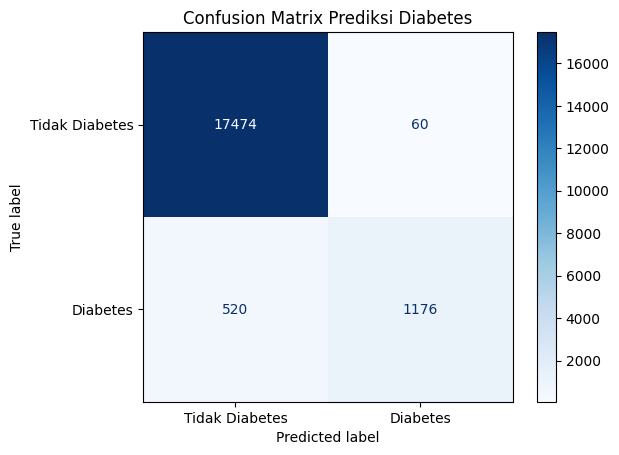

,Fitur,Importance
6,HbA1c_level,0.335407
7,blood_glucose_level,0.268935
1,age,0.193918
5,bmi,0.126975
4,smoking_history,0.031493
2,hypertension,0.023185
3,heart_disease,0.013001
0,gender,0.007087


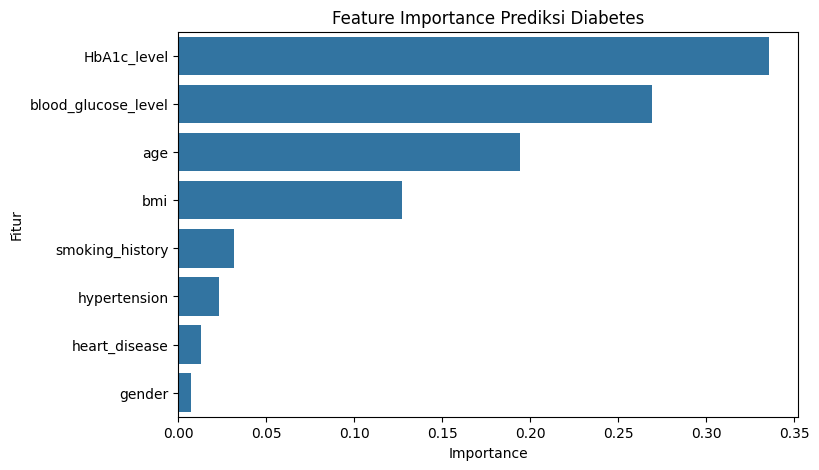

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from google.colab import files

uploaded = files.upload()

data = pd.read_csv('diabetes_prediction_dataset.csv')

print("Data berhasil dibaca")
display(data.head())

print("Ukuran dataset:", data.shape)
print("\nInformasi dataset:")
data.info()

print("\nStatistik deskriptif:")
display(data.describe(include='all'))

print("Missing value:")
print(data.isnull().sum())

print("\nJumlah data duplikat:")
print(data.duplicated().sum())

data = data.drop_duplicates().copy()

data['gender'] = data['gender'].fillna(data['gender'].mode()[0])
data['smoking_history'] = data['smoking_history'].fillna(
    data['smoking_history'].mode()[0]
)

data['age'] = data['age'].fillna(data['age'].median())
data['bmi'] = data['bmi'].fillna(data['bmi'].median())
data['HbA1c_level'] = data['HbA1c_level'].fillna(
    data['HbA1c_level'].median()
)
data['blood_glucose_level'] = data['blood_glucose_level'].fillna(
    data['blood_glucose_level'].median()
)

print("Missing value setelah pembersihan:")
print(data.isnull().sum())
print("\nUkuran data setelah pembersihan:", data.shape)

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='diabetes')
plt.title('Distribusi Data Diabetes')
plt.xlabel('Diabetes (0 = Tidak, 1 = Ya)')
plt.ylabel('Jumlah Data')
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='age', hue='diabetes', bins=30)
plt.title('Distribusi Usia Berdasarkan Status Diabetes')
plt.show()

data_model = data.copy()

encoder = LabelEncoder()

for kolom in ['gender', 'smoking_history']:
    data_model[kolom] = encoder.fit_transform(
        data_model[kolom].astype(str)
    )

print("Data setelah encoding:")
display(data_model.head())

X = data_model.drop('diabetes', axis=1)
y = data_model['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Model berhasil dilatih")

y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi model:", round(akurasi * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Tidak Diabetes', 'Diabetes'],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Tidak Diabetes', 'Diabetes']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix Prediksi Diabetes')
plt.show()

fitur = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': model.feature_importances_
})

fitur = fitur.sort_values(
    by='Importance',
    ascending=False
)

display(fitur)

plt.figure(figsize=(8, 5))
sns.barplot(data=fitur, x='Importance', y='Fitur')
plt.title('Feature Importance Prediksi Diabetes')
plt.show()

data.to_csv('nama_file.csv', index=False)